https://pythonandml.github.io/dlbook/content/preliminaries/data_preprocessing.html

# 1.1. Data Preprocessing

### A. Scaling

**Why Scaling of features is important?**

Our dataset can contain features that vary highly in magnitude and since ML and DL algorithms use Eucledian distance between two data points in their computations, this is a problem. Input variables may have different units (e.g. feet, kilometers, and hours) that, in turn, may mean the variables have different scales. The results would vary greatly between different units, 5kg and 5000gms.

The features with high magnitudes will weigh in a lot more in the distance calculations than features with low magnitudes. To supress this effect, we need to bring all features to the same level of magnitudes and this is where scaling comes into the picture.

**How to Scale Features?**

There are two most common methods to perform Feature Scaling.

#### 1. Standardisation

Standardization typically means rescaling data to have a mean of 0 and a standard deviation of 1 (unit variance).

Standardization assumes that your observations fit a Gaussian distribution (bell curve) with a well behaved mean and standard deviation. You can still standardize your data if this expectation is not met, but you may not get reliable results.

Mathematically it can be expressed as:

$$
Z = \frac{X-\bar{X}}{\sigma}
$$

where $\bar{X}$ and $\sigma$ are the mean and standard deviation of $X$ and $Z$ is the standardized data.

The *standardize(X)* function below implements the standardization of $X$.

> **Note:** If $X$ has many dimensions (or features) and we want to standardize each column individually, then we specify the axis:

In [ ]:
def standardize(X):
    Z = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
    return Z

Generate a random normal distribution (dataset $X$) having 10000 samples with mean ($\bar{X}$) at 1 and standard deviation $(\sigma)$ of 2 and visualize the same

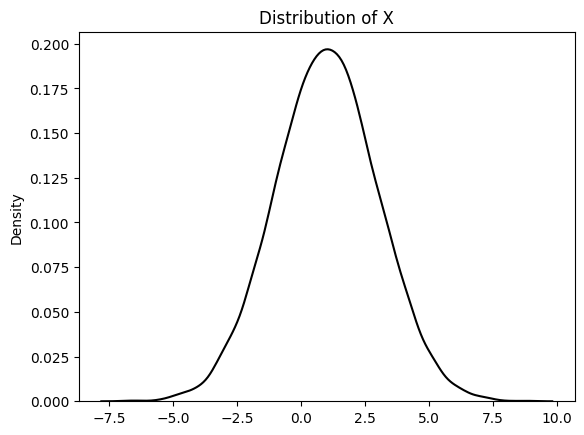

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
X = np.random.normal(size=(10000,1), loc=1, scale=2)

# plot
sns.kdeplot(X[:,0], color='k')
plt.title("Distribution of X")
plt.show()

Now, let us standardize $X$ and visualize it (to demonstrate our function). The complete example is listed below.

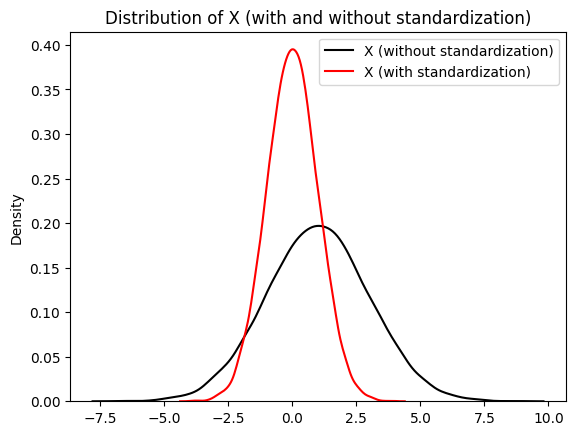

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def standardize(X):
    Z = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
    return Z

np.random.seed(42)
X = np.random.normal(size=(10000,1), loc=1, scale=2)

Z = standardize(X)

# plot
sns.kdeplot(X[:,0], label="X (without standardization)", color='k')
sns.kdeplot(Z[:,0], label="X (with standardization)", color='r')
plt.title("Distribution of X (with and without standardization)")
plt.legend()
plt.show()

#### Validate using Sklearn

Let us validate our function using sklearn's (which is most useful and robust library for machine learning in Python) StandardScaler module. Complete example is listed below

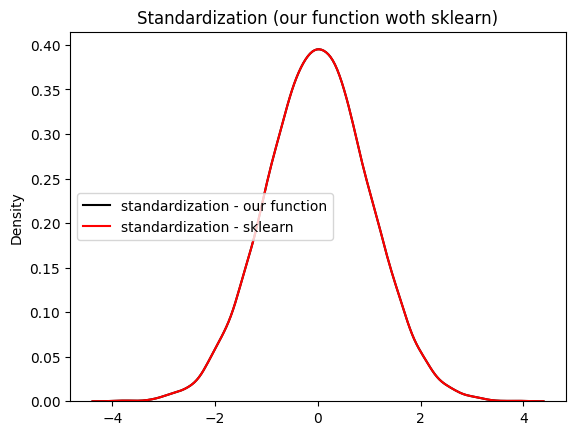

In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def standardize(X):
    Z = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
    return Z

np.random.seed(42)
X = np.random.normal(size=(10000,1), loc=1, scale=2)
Z = standardize(X)

# using sklearn
scaler = StandardScaler()
scaler.fit(X)
Zs = scaler.transform(X)

# plot
sns.kdeplot(Z[:,0], label="standardization - our function", color='k')
sns.kdeplot(Zs[:,0], label="standardization - sklearn", color='r')
plt.title("Standardization (our function woth sklearn)")
plt.legend()
plt.show()

We have successfully validated our function!

#### 2. Min-Max Scaling

In min-max normalization, for every feature (column), its minimum value gets transformed into 0 and its maximum value gets transformed into 1. All values in-between get scaled to be within 0-1 range based on the original value relative to minimum and maximum values of the feature.

Mathematically,

$$
Z = \frac{X-X_{min}}{X_{max}-X_{min}}
$$

Note: If $X$ has many dimensions (or features or columns) and we want to min-max normalize each column individually, then we specify the axis.

The *minmax(X)* function below implements the min-max normalization of $X$.


In [ ]:
def minmax(X):
    Z = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))
    return Z

For the given 1D dataset $X$:

```
X = [1, 2, 3, 4, 5]
```

let us normalize (min-max) $X$ (to demonstrate our function). The complete example is listed below.

In [ ]:
import numpy as np

def minmax(X):
    Z = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))
    return Z

X = np.array([1, 2, 3, 4, 5])
Z = minmax(X)

print("Original dataset (X) =", X)
print("\nX (after min-max normalization) =", Z)

Original dataset (X) = [1 2 3 4 5]

X (after min-max normalization) = [0.   0.25 0.5  0.75 1.  ]


Now consider a 2D dataset $X$ (having 4 samples):

```
X = [[1, 7],
     [4, 3],
     [5, 2],
     [3, 6]]
```

let us min-max normalize $X$. The complete example is listed below.

In [ ]:
import numpy as np

def minmax(X):
    Z = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))
    return Z

X = np.array([[1, 7],
              [4, 3],
              [5, 2],
              [3, 6]])
Z = minmax(X)

print("Original dataset (X) =\n\n", X)
print("\nX (after min-max normalization) =\n\n", Z)

Original dataset (X) =

 [[1 7]
 [4 3]
 [5 2]
 [3 6]]

X (after min-max normalization) =

 [[0.   1.  ]
 [0.75 0.2 ]
 [1.   0.  ]
 [0.5  0.8 ]]


#### Validate using Sklearn

Let us validate our function using sklearn's MinMaxScaler module. Complete example is listed below

In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

def minmax(X):
    Z = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))
    return Z

X = np.array([[1, 7],
              [4, 3],
              [5, 2],
              [3, 6]])
Z = minmax(X)

scaler = MinMaxScaler()
scaler.fit(X)
Zs = scaler.transform(X)

print("Original dataset (X) =\n\n", X)
print("\nMin-Max normalization - our function =\n\n", Z)
print("\nMin-Max normalization - sklearn =\n\n", Zs)

Original dataset (X) =

 [[1 7]
 [4 3]
 [5 2]
 [3 6]]

Min-Max normalization - our function =

 [[0.   1.  ]
 [0.75 0.2 ]
 [1.   0.  ]
 [0.5  0.8 ]]

Min-Max normalization - sklearn =

 [[0.   1.  ]
 [0.75 0.2 ]
 [1.   0.  ]
 [0.5  0.8 ]]


We have successfully validated our function!

### B. Encoding

Most algorithms cannot work with categorical data and needs to be converted into numerical data. Sometimes in datasets, we encounter columns that contain categorical features (string values) for example parameter **Gender** will have categorical parameters like *Male*, *Female*.

Suppose we have the following fictional dataset $X$ with 7 samples (rows) and 3 features (or dimensions or columns; 2 categorical columns *Fruits* and *Vegetables* and 1 numerical column *Value*)

| Fruits  | Vegetables | Value |
| ------- | ---------- | ----- |
| स्याउ   | गोलभेंडा   | 8     |
| आँप     | गोलभेंडा   | 3     |
| स्याउ   | गाजर       | 7     |
| सुन्तला | आलु        | 4     |
| मेवा    | गाजर       | 6     |
| केरा    | गोलभेंडा   | 7     |
| सुन्तला | आलु        | 7     |


#### 1. Label Encoding

One approach to solve this problem can be label encoding where we will assign a numerical value to these labels for example Male and Female mapped to 0 and 1.

The *label_encoding(Y)* function implemented below performs label encoding of the categorical data $Y$ and returns the label encoded data of $Y$ along with a list of the dictionaries containing the unique values of the columns and their mapping to the integer.

> **Note:** $Y$ must have only categorical columns (like *Fruits* and *Vegetables* only and **NOT** the *Value* column from the above dataset $X$)

In [ ]:
def label_encoding(Y):
    '''
    Parameters:
    Y: (m,d) shape matrix with categorical data
    Return
    result: label encoded data of 𝑌
    idx_list: list of the dictionaries containing the unique values
              of the columns and their mapping to the integer.
    '''
    idx_list = []
    result = []
    for col in range(Y.shape[1]):
        indexes = {val: idx for idx, val in enumerate(np.unique(Y[:, col]))}
        result.append([indexes[s] for s in Y[:, col]])
        idx_list.append(indexes)
    return np.array(result).T, idx_list

Consider the given dataset $X$ and we want to perform label encoding of $X$ using the function developed above. Complete example is listed below.

In [ ]:
import numpy as np

def label_encoding(Y):
    '''
    Parameters:
    Y: (m,d) shape matrix with categorical data
    Return
    result: label encoded data of 𝑌
    idx_list: list of the dictionaries containing the unique values
              of the columns and their mapping to the integer.
    '''
    idx_list = []
    result = []
    for col in range(Y.shape[1]):
        indexes = {val: idx for idx, val in enumerate(np.unique(Y[:, col]))}
        result.append([indexes[s] for s in Y[:, col]])
        idx_list.append(indexes)
    return np.array(result).T, idx_list

X = np.array([
    ['स्याउ', 'गोलभेंडा', 8],
    ['आँप', 'गोलभेंडा', 3],
    ['स्याउ', 'गाजर', 7],
    ['सुन्तला', 'आलु', 4],
    ['मेवा', 'गाजर', 6],
    ['केरा', 'गोलभेंडा', 7],
    ['सुन्तला', 'आलु', 7]
], dtype=object)

Y = X[:, :-1]
Y_label_enc, idx_list = label_encoding(Y)

print("Categorical dataset (Y) =\n\n", Y)
print("\nMapping List of Dictionaries =\n\n", idx_list)
print("\nLabel Encoding of Y =\n\n", Y_label_enc)

Categorical dataset (Y) =

 [['स्याउ' 'गोलभेंडा']
 ['आँप' 'गोलभेंडा']
 ['स्याउ' 'गाजर']
 ['सुन्तला' 'आलु']
 ['मेवा' 'गाजर']
 ['केरा' 'गोलभेंडा']
 ['सुन्तला' 'आलु']]

Mapping List of Dictionaries =

 [{'आँप': 0, 'केरा': 1, 'मेवा': 2, 'सुन्तला': 3, 'स्याउ': 4}, {'आलु': 0, 'गाजर': 1, 'गोलभेंडा': 2}]

Label Encoding of Y =

 [[4 2]
 [0 2]
 [4 1]
 [3 0]
 [2 1]
 [1 2]
 [3 0]]


We see here that in the Fruits column, "Apple" is mapped to 0, Banana to 1 and so on. Similarly, in the Vegetables column, "Carrot" is mapped to 0, Potato to 1 and Tomato to 2.

After getting this mapping list, we have our final label encoded matrix

#### 2. One-Hot encoding

In this technique, the categorical parameters will prepare separate columns for all the labels. So, wherever there is Male, the value will be 1 in Male column and 0 in Female column, and vice-versa.

Let us understand this with a simple example where data $X$ is:

| Fruits  |
| ------- |
| स्याउ   |
| आँप     |
| स्याउ   |
| स्याउ   |
| सुन्तला |
| आँप     |

Notice that $X$ has only 3 unique values "Apple", "Mango" and "Orange". So, the One-Hot encoded matrix of $X$ will look like:

| Fruit   | स्याउ | आँप | सुन्तला |
| ------- | ------------- | ----------- | ---------------- |
| स्याउ   | 1             | 0           | 0                |
| आँप     | 0             | 1           | 0                |
| स्याउ   | 1             | 0           | 0                |
| स्याउ   | 1             | 0           | 0                |
| सुन्तला | 0             | 0           | 1                |
| आँप     | 0             | 1           | 0                |


Just observe that wherever we have "Apple" in the *Fruits* column, the column *Apple* contains value 1 and 0 otherwise. Similarly, wherever we have "Mango" or "Orange" in the *Fruits* column, the columns *Mango* and *Orange* contains value 1 and 0 otherwise respectively.

> **Note:** The order of the columns *Apple*, *Mango* or *Orange* can change

The *onehot(X)* function implemented below performs one hot encoding of the categorical data $X$ and returns the one hot encoded data of $X$ along with a dictionary containing the unique values of $X$ and their mapping to the integer column (as orders can change).


In [ ]:
def onehot(X):
    '''
    Parameters:
    X: 1D array of labels of length "m"
    Return
    X_onehot: (m,d) one hot encoded matrix (one-hot of X)
              (where d is the number of unique values in X)
    indexes: dictionary containing the unique values of X and their mapping to the integer column
    '''
    indexes = {val: idx for idx, val in enumerate(np.unique(X))}
    y = np.array([indexes[s] for s in X])
    X_onehot = np.zeros((y.size, len(indexes)))
    X_onehot[np.arange(y.size), y] = 1
    return X_onehot, indexes

Consider the dataset from above example $X$ and we want to perform one hot encoding of $X$ using the function developed above. Complete example is listed below.

In [ ]:
import numpy as np

def onehot(X):
    '''
    Parameters:
    X: 1D array of labels of length "m"
    Return
    X_onehot: (m,d) one hot encoded matrix (one-hot of X)
              (where d is the number of unique values in X)
    indexes: dictionary containing the unique values of X and their mapping to the integer column
    '''
    indexes = {val: idx for idx, val in enumerate(np.unique(X))}
    y = np.array([indexes[s] for s in X])
    X_onehot = np.zeros((y.size, len(indexes)))
    X_onehot[np.arange(y.size), y] = 1
    return X_onehot, indexes

X = np.array(['स्याउ', 'आँप', 'स्याउ', 'स्याउ', 'सुन्तला', 'आँप'])

X_onehot, indexes = onehot(X)

print("Given dataset (X) =\n\n", X.reshape(-1,1))
print("\nMapping Dictionary =", indexes)
print("\nOne Hot Encoding of X =\n\n", X_onehot)

Given dataset (X) =

 [['स्याउ']
 ['आँप']
 ['स्याउ']
 ['स्याउ']
 ['सुन्तला']
 ['आँप']]

Mapping Dictionary = {np.str_('आँप'): 0, np.str_('सुन्तला'): 1, np.str_('स्याउ'): 2}

One Hot Encoding of X =

 [[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]


# 1.2. Performance Metrics for ML and DL models

### Why We require Evaluation Metrics?

Any model in real world cannot have 100% efficiency otherwise the model is known as a biased model. Although it is necessary to obtain the accuracy on training data, it is also important to get a genuine and approximate result on unseen data otherwise Model is of no use.

So to build and deploy a generalized model we require to Evaluate the model on different metrics which helps us to better optimize the performance, fine-tune it, and obtain a better result. So, let’s start exploring different Evaluation metrics.

### A) Evaluation Metrics for Regression





Suppose we have the actual ($y$) and the predicted ($\hat{y}$) values of the target variable $y$ (from any model) and we want to evaluate it using different metrics

In [ ]:
actual = [1,2,3,4,5,6]
predicted = [1,3,4,4,5,9]

#### 1) Mean Absolute Error (MAE)

MAE is a very simple metric which calculates the absolute difference between actual and predicted values. Basically, sum all the errors and divide them by a total number of observations and this is MAE.

![](images/mae.jpeg)

**Advantages of MAE**

*   The MAE you get is in the same unit as the output variable
*   It is most Robust to outliers

**Disadvantages of MAE**

*   The graph of MAE is not differentiable so we have to apply various optimizers like Gradient descent




In [ ]:
import numpy as np

def mae(actual, predicted):
    actual, predicted = np.array(actual), np.array(predicted)
    return np.mean(np.abs(actual - predicted))

In [ ]:
print("MAE =", round(mae(actual, predicted),3))

MAE = 0.833


#### 2) Mean Absolute Percentage Error (MAPE)

MAPE is the mean absolute percentage error, which is a relative measure that essentially scales MAE to be in percentage units instead of the variable’s units.

![](images/mape.png)

**Advantages of MAPE**

*   It is one of the most widely used measures of forecast accuracy, due to its advantages of **scale-independency** and **interpretability**.

**Disadvantages of MAPE**

*   It has the significant disadvantage that it produces infinite or undefined values for zero or close-to-zero actual values




In [ ]:
import numpy as np

def mape(actual, predicted):
    actual, predicted = np.array(actual), np.array(predicted)
    return np.mean(np.abs((actual - predicted)/actual))

In [ ]:
print("MAPE =", round(mape(actual, predicted),3))

MAPE = 0.222


#### 3) Mean Squared Error (MSE)

MSE is a most used and very simple metric with a little bit of change in mean absolute error. Mean squared error states that finding the squared difference between actual and predicted value.

![](images/mse.png)

**Advantages of MSE**

*   The graph of MSE is differentiable, so you can easily use it as a loss function

**Disadvantages of MSE**

*   The value you get after calculating MSE is a squared unit of output. for example, the output variable is in meter(m) then after calculating MSE the output we get is in meter squared
*   If you have outliers in the dataset then it penalizes the outliers most and the calculated MSE is bigger. So, in short, It is not robust to outliers which were an advantage in MAE




In [ ]:
import numpy as np

def mse(actual, predicted):
    actual, predicted = np.array(actual), np.array(predicted)
    return np.mean((actual - predicted)**2)

In [ ]:
print("MSE =", round(mse(actual, predicted),3))

MSE = 1.833


#### 4) Root Mean Squared Error (RMSE)

As the name itself suggests, RMSE is simply the square root of MSE

![](images/rmse.png)

**Advantages of RMSE**

*   The output value you get is in the same unit as the required output variable which makes interpretation of loss easy.

**Disadvantages of MSE**

*   It is also not that robust to outliers as compared to MAE.




In [ ]:
import numpy as np

def rmse(actual, predicted):
    actual, predicted = np.array(actual), np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

In [ ]:
print("RMSE =", round(rmse(actual, predicted),3))

RMSE = 1.354


#### 5) Coefficient of Determination (R-squared or $R^2$)**

Coefficient of Determination or R-squared value measures the strength of the relationship between your linear model and the dependent variables on a 0 - 1 scale. It represents the proportion of the variance for a dependent variable that's explained by an independent variable.

$$
R^2 = 1-\frac{\sum_{i=1}^{n}(y_i-\hat y_i )^2}{\sum_{i=1}^{n}(y_i-\bar y)^2}
$$

#### y = actual output

#### $\hat y$ = predicted output

#### $\bar y$ = mean value of y

#### n = number of samples or data points



**<font color='darkgreen'>How to interpret $R^2$ value</font>**

Now if this $R^2$ score is 0, then there is no correlation between $y$ and $\hat y$ and if it is 1, then we have 100% correlation between these values (best model).

The normal case is when the $R^2$ score is between 0 and 1 like 0.8 which means our model is capable to explain 80% variation for a dependent variable by an independent variable.

**Note:** Negative values of $𝑅^2$ may occur when fitting non-linear functions to data. In cases where negative values arise, the mean of the data provides a better fit to the outcomes than do the fitted function values, according to this particular criterion.


In [ ]:
import numpy as np

def r2_score(actual, predicted):
    actual, predicted = np.array(actual), np.array(predicted)
    rss = np.sum((actual - predicted)**2)
    tss = np.sum((actual - np.mean(actual))**2)
    return 1-(rss/tss)

In [ ]:
print("R2 score =", round(r2_score(actual, predicted),3))

R2 score = 0.371


#### 6) Adjusted R-squared

The disadvantage of the $R^2$ score is that while adding new features in data the $R^2$ score starts increasing or remains constant but it never decreases because It assumes that while adding more data, variance of data increases.

But when we add an irrelevant feature in the dataset then at that time $R^2$ sometimes starts increasing which is incorrect.

Hence, to control this situation Adjusted R-Squared $R_a^2$ came into existence.

$$
R_a^2 = 1-\frac{(1-R^2)(n-1)}{(n-k-1)}
$$

#### $R^2$ = R-squared value

#### n = number of samples or data points

#### k = number of independent variables or number of predictors/ features



In [ ]:
import numpy as np

def adjusted_r2_score(R2, n, k):
    return 1 - ((1-R2)*(n-1)/(n-k-1))

In [ ]:
R2 = r2_score(actual, predicted)
n, k = len(actual), 3
print("adjusted R2 score =", round(adjusted_r2_score(R2, n, k),3))

adjusted R2 score = -0.571


### B) Evaluation Metrics for Classification





### 1) Confusion Matrix

Confusion matrix is a table with combinations of predicted and actual values. It is a matrix that compares the number of predictions for each class that are correct and those that are incorrect.

The confusion matrix is a **N x N matrix**, where <font color='blue'>N is the number of classes</font> or outputs.

For 2 class, we get 2 x 2 confusion matrix.

For 3 class, we get 3 X 3 confusion matrix.

In a confusion matrix, there are 4 numbers to pay attention which are **True Positive(TP), False Positive(FP), True Negative(TN) and False Negative(FN)**.

### How does the confusion matrix look like?

Below is the representation of the confusion matrix.

![](images/cm.jpeg)


### Confusion matrix for Binary Classification

Let us understand the confusion matrix for a **simple binary classification example**.

Binary classification has 2 outputs, the inputs for this classification will fall in either of the 2 outputs or classes. Let us see how to construct a confusion matrix and understand its terminologies.

#### Example

Consider we have to model a classifier that classifies 2 kinds of fruits.

Suppose have **<font color='black'>2 types of fruits Apples and Grapes</font>** and we want our machine learning model to identify or classify the given fruit as an Apple or Grape.

Assume we take **15 samples**, out of which **<font color='red'>8 belong to Apples</font>** and **<font color='green'>7 belong to the Grapes</font>**. We will **represent Apple as 1** (we can also call it as *Negative class*) and **Grape as 0** (we can also call it as *Positive class*).

Let the actual class for 8 apples and 7 grapes, be represented as

<font color='blue'>actual = [1,1,1,1,1,1,1,1,0,0,0,0,0,0,0]</font>

Assume that the **classifier** takes all the 15 inputs and, makes the following **predictions**:

*  Out of **<font color='red'>8 Apples</font>**, it will classify **<font color='red'>5 correctly as Apples</font>** and **<font color='green'>wrongly predict 3 as grapes</font>**

*  Out of **<font color='green'>7 grapes</font>**, it will classify **<font color='green'>5 correctly as grapes</font>** and **<font color='red'>wrongly predicts 2 as apples</font>**

The prediction of the classifier may be as follows:

<font color='blue'>predicted = [1,0,0,0,1,1,1,1,0,0,0,0,0,1,1]</font>





In [ ]:
import numpy as np
import pandas as pd

In [ ]:
def confusion_matrix(actual, predicted, label_name, margins=False):
    actual = pd.Series(actual, name='Actual')
    predicted = pd.Series(predicted, name='Predicted')
    df_confusion = pd.crosstab(actual, predicted, rownames=['Actual'], colnames=['Predicted'], margins=margins)
    df_confusion.rename(index=label_name, columns=label_name, inplace=True)
    return df_confusion

In [ ]:
label_name = {0:'अंगुर', 1: 'स्याउ'}
actual = [1,1,1,1,1,1,1,1,0,0,0,0,0,0,0]
predicted = [1,0,0,0,1,1,1,1,0,0,0,0,0,1,1]

In [ ]:
df_confusion = confusion_matrix(actual, predicted, label_name)
print("Confusion Matrix")
df_confusion

Confusion Matrix


Predicted,अंगुर,स्याउ
Actual,,
अंगुर,5,2
स्याउ,3,5


### True Positive (TP)

We predicted positive class (here grapes) and the actual class is also grape. So, from the above example, **TP=5**

### True Negative (TN)

We predicted negative class (here an apple) and the actual class is also an apple. So, from the above example, **TN=5**

### False Positive (FP, Type 1 Error)

We predicted positive class (grape) and it is **false**, the actual class is an apple (negative class). So, from the above example, **FP=3**

### False Negative (FN, Type 2 Error)

We predicted negative class (apple) and it is false, the actual class is a grape (positive class). So, from the above example, **FN=2**

### Confusion Matrix for Multiclass Classification

In the multi-class classification problem, we won’t get TP, TN, FP, and FN values directly as in the binary classification problem. We need to calculate them separately for each class and this makes sense as well (if we have properly understood the definitions of these terms).

**FN**: The False-negative value for a class will be the sum of values of corresponding rows except for the TP value.

**FP**: The False-positive value for a class will be the sum of values of the corresponding column except for the TP value.

**TN**: The True Negative value for a class will be the sum of values of all columns and rows except the values of that class that we are calculating the values for (because we are not bothered with any other class except for the class in consideration).

**TP**: The True positive value is where the actual value and predicted value are the same.

Consider the table below showing TP, TN, FP, and FN values for class-0 (where we have 3 classes namely **class-0**, **class-1** and **class-2**)

![](images/tpfp.png)

#### TP, TN, FP, FN values using numpy and pandas

Consider the following actual and predicted values

```
actual = [1, 2, 0, 0, 1, 2, 1, 0, 2, 0, 1, 2, 1, 0, 0, 2, 0]
predicted = [2, 2, 1, 0, 0, 0, 0, 2, 1, 2, 1, 1, 0, 0, 1, 1, 2]
```

In [ ]:
def CM_parameters(cnf_matrix):
    FP = cnf_matrix.sum(axis=0) - np.diag(cnf_matrix)
    FN = cnf_matrix.sum(axis=1) - np.diag(cnf_matrix)
    TP = np.diag(cnf_matrix)
    TN = cnf_matrix.sum() - (FP + FN + TP)
    return TP.astype(float), TN.astype(float), FP.astype(float), FN.astype(float)

In [ ]:
# Example

actual = [1, 2, 0, 0, 1, 2, 1, 0, 2, 0, 1, 2, 1, 0, 0, 2, 0]
predicted = [2, 2, 1, 0, 0, 0, 0, 2, 1, 2, 1, 1, 0, 0, 1, 1, 2]
label_name = {0:'Class-0', 1: 'Class-1', 2: 'Class-2'}

df_confusion = confusion_matrix(actual, predicted, label_name)
print("Confusion Matrix")
df_confusion

Confusion Matrix


Predicted,Class-0,Class-1,Class-2
Actual,,,
Class-0,2,2,3
Class-1,3,1,1
Class-2,1,3,1


In [ ]:
cnf_matrix = df_confusion.values
TP, TN, FP, FN = CM_parameters(cnf_matrix)

In [ ]:
TP

array([2., 1., 1.])

So, for **class-0**, TP is 2, for **class-1**, TP is 1 and for **class-2** also, TP = 1. Similarly we get TN, FP and FN values

In [ ]:
TN

array([6., 7., 8.])

In [ ]:
FP

array([4., 5., 4.])

In [ ]:
FN

array([5., 4., 4.])

### Well known performance metrics calculated using TP, TN, FP and FN

#### 1) Accuracy

Accuracy simply measures how often the classifier correctly predicts. We can define accuracy as the ratio of the number of correct predictions and the total number of predictions. We can calculate accuracy both globally (for the entire model) and individually for each class.

**Note:** Let us assume we have **<font color='red'>C</font>** number of classes and number of samples or data points is **<font color='red'>N</font>**

#### a) Accuracy for each class

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$
<br>

#### b) Global Accuracy

$$
Accuracy_g = \frac{\sum_{i=1}^{C} TP_i}{N}
$$
<br>

When any model gives an accuracy rate of 99%, you might think that model is performing very good but this is not always true and can be misleading in some situations.

Accuracy is useful when the output class is **well balanced** but is not a good choice for the **imbalanced data**. Imagine the scenario where we have <font color='blue'>98 images of the dog</font> and only <font color='green'>2 images of a cat</font> present in our training data. If our model predicted all the images as dogs, then our model achieved **98% accuracy** which is mis-leading.

Hence, if we want to do a better model evaluation and have a full picture of the model evaluation, other metrics such as recall, precision, etc should also be considered.



In [ ]:
accuracy = (TP+TN) / (TP+TN+FP+FN)
print("Accuracy for each class =", np.round(accuracy, 3))

Accuracy for each class = [0.471 0.471 0.529]


In [ ]:
accuracy_g = np.sum(TP) / len(actual)
print("Global Accuracy =", round(accuracy_g, 3))

Global Accuracy = 0.235


#### 2) Precision

It tells you what fraction of predictions as a positive class were actually positive. Precision is useful in the cases where **False Positive is a higher concern than False Negatives**. It is also known as **Positive Predictive Value**

The importance of Precision is in music or video recommendation systems, e-commerce websites, etc. where wrong results could lead to customer churn and this could be harmful to the business.

$$
Precision = \frac{TP}{TP+FP}
$$
<br>


In [ ]:
precision = TP / (TP+FP)
print("Precision for each class =", np.round(precision, 3))

Precision for each class = [0.333 0.167 0.2  ]


#### 3) Recall

It tells you what fraction of all positive samples were correctly predicted as positive by the classifier. It is also known as **True Positive Rate (TPR), Sensitivity, Probability of Detection and Hit rate**.

It is a useful metric in cases where **False Negative is of higher concern than False Positive**. It is important in medical cases where it doesn’t matter whether we raise a false alarm but the actual positive cases should not go undetected!

$$
Recall = \frac{TP}{TP+FN}
$$
<br>



In [ ]:
recall = TP / (TP+FN)
print("Recall for each class =", np.round(recall, 3))

Recall for each class = [0.286 0.2   0.2  ]


#### 4) Specificity

It tells you what fraction of all negative samples are correctly predicted as negative by the classifier. It is also known as **True Negative Rate (TNR)**.

$$
Specificity = \frac{TN}{TN+FP}
$$
<br>



In [ ]:
specificity = TN / (TN+FP)
print("Specificity for each class =", np.round(specificity, 3))

Specificity for each class = [0.6   0.583 0.667]


#### 5) Fall out or False Positive Rate (FPR) and False Negative Rate (FNR)

$$
FPR = \frac{FP}{FP+TN}
$$
<br>

$$
FNR = \frac{FN}{TP+FN}
$$

In [ ]:
FPR = FP / (FP+TN)
print("False Positive Rate for each class =", np.round(FPR, 3))
FNR = FN / (TP+FN)
print("False Negative Rate for each class =", np.round(FNR, 3))

False Positive Rate for each class = [0.4   0.417 0.333]
False Negative Rate for each class = [0.714 0.8   0.8  ]


#### 6) F1-score

It gives a combined idea about Precision and Recall metrics. It is maximum when Precision is equal to Recall. F1 Score is the **harmonic mean of precision and recall**. The F1 score punishes extreme values more.

$$
F1 = \frac{2*Precision*Recall}{Precision+Recall}
$$
<br>

We can **combine the F1-score of each class** to have a single measure for the whole model. There are a few ways to do that, let’s look at them now.


In [ ]:
f1 = 2*precision*recall / (precision+recall)
print("F1-score for each class =", np.round(f1, 3))

F1-score for each class = [0.308 0.182 0.2  ]


#### 7) Micro scores (Micro Precision, Recall and F1)

This is called **micro-averaged score**. It is calculated by considering the total TP, total FP and total FN of the model. It does not consider each class individually, It calculates the metrics globally. So for our example,

**Total TP** $= \sum TP = 2 + 1 + 1 = 4$

**Total FP** $= \sum FP = 4+5+4 = 13$

**Total FN** $= \sum FN = 5+4+4 = 13$

So,

**Total Precision** $= 4/(4+13) = 4/17$

**Total Recall** $= 4/(4+13) = 4/17$

Now we can use the regular formula for F1-score and get the Micro F1-score using the above precision and recall.

**Micro-F1** $= 0.2353$

As you can see When we are calculating the metrics globally all the measures become equal. Also if you calculate accuracy you will see that,

**Total Precision = Total Recall = Micro-F1 = Global Accuracy**



In [ ]:
Total_TP = np.sum(TP)
Total_FP = np.sum(FP)
Total_FN = np.sum(FN)

micro_precision = Total_TP / (Total_TP + Total_FP)
print("Micro Precision =", round(micro_precision, 3))

micro_recall = Total_TP / (Total_TP + Total_FN)
print("Micro Recall =", round(micro_recall, 3))

micro_f1 = 2*micro_precision*micro_recall / (micro_precision + micro_recall)
print("Micro F1-score =", round(micro_f1, 3))

Micro Precision = 0.235
Micro Recall = 0.235
Micro F1-score = 0.235


#### 8) Macro scores (Macro Precision, Recall and F1)

It calculates metrics for each class individually and then takes unweighted mean of the measures. For example if,

Class-0 F1-score = 0.308

Class-1 F1-score = 0.182

Class-2 F1-score = 0.2

Hence,

**Macro F1** $= (0.308+0.182+0.2)/3 = 0.23$


In [ ]:
macro_precision = np.mean(precision)
print("Macro Precision =", round(macro_precision, 3))

macro_recall = np.mean(recall)
print("Macro Recall =", round(macro_recall, 3))

macro_f1 = np.mean(f1)
print("Macro F1-score =", round(macro_f1, 3))

Macro Precision = 0.233
Macro Recall = 0.229
Macro F1-score = 0.23



#### 9) Weighted scores (Weighted Precision, Recall and F1)

Unlike Macro F1, it takes a weighted mean of the measures. The weights for each class are the total number of samples of that class.

Suppose we have **7 Class-0 samples, 5 Class-1 samples and 5 Class-2 samples**, and

Class-0 F1-score = 0.308

Class-1 F1-score = 0.182

Class-2 F1-score = 0.2

Hence,

**Weighted F1** $= ((0.308*7)+(0.182*5)+(0.2*5))/(7+5+5) = 0.24$

In [ ]:
class_samples = TP+FN

weighted_precision = np.sum(class_samples*precision)/np.sum(class_samples)
print("Weighted Precision =", round(weighted_precision, 3))

weighted_recall = np.sum(class_samples*recall)/np.sum(class_samples)
print("Weighted Recall =", round(weighted_recall, 3))

weighted_f1 = np.sum(class_samples*f1)/np.sum(class_samples)
print("Weighted F1-score =", round(weighted_f1, 3))

Weighted Precision = 0.245
Weighted Recall = 0.235
Weighted F1-score = 0.239


### Confirming the values using sklearn's classification report

In [ ]:
from sklearn.metrics import classification_report

target_names = ['class-0', 'class-1', 'class-2']
print(classification_report(actual, predicted, target_names=target_names))

              precision    recall  f1-score   support

     class-0       0.33      0.29      0.31         7
     class-1       0.17      0.20      0.18         5
     class-2       0.20      0.20      0.20         5

    accuracy                           0.24        17
   macro avg       0.23      0.23      0.23        17
weighted avg       0.25      0.24      0.24        17



Perfect! The values turn out to be same

#### 10) F-beta score

It measures the effectiveness of retrieval with respect to a user who attaches $β^2$ times as much importance to recall as precision. That is: $\mathrm{weight_{Recall}} = \beta^2 \times \mathrm{weight_{Precision}}$. Check out this [link](https://stats.stackexchange.com/questions/221997/why-f-beta-score-define-beta-like-that/379474#379474) for more detail.

$$
F_\beta = (1 + \beta^2) \cdot \frac{\mathrm{precision} \cdot \mathrm{recall}}{(\beta^2 \cdot \mathrm{precision}) + \mathrm{recall}}
$$
<br>

So, if **β = 1**, equal weights are attached to both:

$$
F_1 = \frac{1}{\frac{1}{2}\frac{1}{\text{precision}}+\frac{1}{2}\frac{1}{\text{recall}}} \\
= 2\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}
$$
<br>

If **β = 2**,

$$
F_2 = \frac{1}{\frac{1}{5}\frac{1}{\text{precision}}+\frac{4}{5}\frac{1}{\text{recall}}} \\
= 5 \cdot\frac{\text{precision}\cdot\text{recall}}{(4 \cdot\text{precision})+\text{recall}}
$$
<br>

In [ ]:
beta = 2

fbeta = (1+beta**2)*precision*recall / (((beta**2)*precision)+recall)
print("F-(beta=" + str(beta) + ") score for each class =", np.round(fbeta, 3))

F-(beta=2) score for each class = [0.294 0.192 0.2  ]


In [ ]:
macro_fbeta = np.mean(fbeta)
print("Macro F-(beta=" + str(beta) + ") =", round(macro_fbeta, 3))

Macro F-(beta=2) = 0.229


In [ ]:
weighted_fbeta = np.sum(class_samples*fbeta)/np.sum(class_samples)
print("Weighted F-(beta=" + str(beta) + ") =", round(weighted_fbeta, 3))

Weighted F-(beta=2) = 0.236


### Confirm using sklearn's fbeta_score metric

In [ ]:
from sklearn.metrics import fbeta_score

weighted_fbeta_sk = fbeta_score(y_true=actual, y_pred=predicted, beta=2, average='weighted')
print("Sklearn's Weighted F-(beta=" + str(beta) + ") =", round(weighted_fbeta_sk, 3))

Sklearn's Weighted F-(beta=2) = 0.236


#### **11) Cohen's kappa statistic**

The Kappa statistic (or value) is a metric that compares an **Observed Accuracy** with an **Expected Accuracy** (random chance). The kappa statistic is used not only to evaluate a single classifier, but also to evaluate classifiers amongst themselves.

Cohen’s kappa measures the agreement between **two raters who each classify N items into C mutually exclusive categories**.

Computation of **Observed Accuracy** and **Expected Accuracy** is integral to comprehension of the kappa statistic, and is most easily illustrated through use of a confusion matrix. Lets begin with a simple confusion matrix from a simple binary classification of Apples and Grapes (our original example):

![](images/cross_tab.png)


From the **confusion matrix** we can see there are **15 instances total** (5 + 2 + 3 + 5 = 15). According to the first row **7 were labeled as Grapes** (5 + 2 = 7), and according to the second row **8 were labeled as Apples** (3 + 5 = 8). We can also see that the **<font color='green'>model classified 8 instances as Grapes</font>** (5 + 3 = 8) and **<font color='red'>7 instances as Apples</font>** (2 + 5 = 7).

To calculate **Cohen's kappa**, **Observed Accuracy** and **Expected Accuracy** are required.

**Observed Accuracy (OA)**

Observed accuracy is simply the **Global Accuracy of the model** which we have mentioned above. Here, **OA = (5+5)/(5+5+2+3) = 10/15= 0.667**

**Expected Accuracy (EA)**

This value is defined as the accuracy that any random classifier would be expected to achieve based on the confusion matrix.

**Follow these steps to calculate Expected Accuracy (EA)**

In our case, **7 samples were labeled as Grapes** (5 + 2 = 7) which is marginal frequency of ground label, and the **<font color='green'>model classified 8 instances as Grapes</font>** (5 + 3 = 8) which is marginal frequency of the predicted label.

This results in a value of **3.734** (7 * 8 / Total samples = 7 * 8 / 15 = 3.734) which is **marginal frequency of Grapes**.

This is then done for the second class as well (and can be repeated for each additional class if there are more than 2).

Then **3.734** (8 * 7 / Total samples = 8 * 7 / 15 = 3.734) is the **marginal frequency of Apples**.

The final step is to add all these values together, and finally divide again by the total number of instances, resulting in an **Expected Accuracy (EA) of 0.4977** ((3.734 + 3.734)/15)

$$
\mathrm{kappa} = \frac{OA-EA}{1-EA}
$$
<br>

So, in our case, the **kappa statistic** equals: (0.667 - 0.4977)/(1 - 0.4977) = **0.3363**.

**Interpreting the Kappa value obtained**

There is not a standardized interpretation of the kappa statistic. According to Wikipedia (citing their paper):

Landis and Koch considers **0-0.20 as slight, 0.21-0.40 as fair, 0.41-0.60 as moderate, 0.61-0.80 as substantial, and 0.81-1 as almost perfect**.

Fleiss considers **kappas > 0.75 as excellent, 0.40-0.75 as fair to good, and < 0.40 as poor**. It is important to note that both scales are somewhat arbitrary.


In [ ]:
def cohen_kappa(actual, predicted, label_name={}):
    df_confusion = confusion_matrix(actual, predicted, label_name, margins=True)
    n = len(actual)
    OA = np.sum(np.diag(df_confusion.values)[:-1])/n
    col_comb = df_confusion['All'].values[:-1]
    row_comb = df_confusion.loc['All'].values[:-1]
    EA = np.sum(row_comb*col_comb)/(n**2)
    kappa = (OA-EA)/(1-EA)
    return kappa

In [ ]:
label_name = {0:'Grapes', 1: 'Apples'}
actual = [1,1,1,1,1,1,1,1,0,0,0,0,0,0,0]
predicted = [1,0,0,0,1,1,1,1,0,0,0,0,0,1,1]

In [ ]:
kappa = cohen_kappa(actual, predicted)
print("Cohen's Kappa =", round(kappa, 3))

Cohen's Kappa = 0.336


### Confirm the same using Sklearn's cohen_kappa_score

In [ ]:
from sklearn.metrics import cohen_kappa_score

kappa_sk = cohen_kappa_score(actual, predicted)
print("Sklearn's Cohen's Kappa =", round(kappa_sk, 3))

Sklearn's Cohen's Kappa = 0.336


### Testing the same on 3-classes

In [ ]:
actual = [1, 2, 0, 0, 1, 2, 1, 0, 2, 0, 1, 2, 1, 0, 0, 2, 0]
predicted = [2, 2, 1, 0, 0, 0, 0, 2, 1, 2, 1, 1, 0, 0, 1, 1, 2]
label_name = {0:'Class-0', 1: 'Class-1', 2: 'Class-2'}

In [ ]:
kappa = cohen_kappa(actual, predicted)
print("Cohen's Kappa =", round(kappa, 3))

Cohen's Kappa = -0.151


In [ ]:
kappa_sk = cohen_kappa_score(actual, predicted)
print("Sklearn's Cohen's Kappa =", round(kappa_sk, 3))

Sklearn's Cohen's Kappa = -0.151


#### 12) Jaccard Similarity Index

If two sets share the **exact same members**, their **Jaccard Similarity Index will be 1**. Conversely, if they have **no members in common** then their **similarity will be 0**.

So, the idea behind this index is that higher the similarity of these two groups (actual and predicted labels) the higher the index.



In [ ]:
def jaccard_similarity(actual, predicted):
    n = np.sum(np.array(actual)==np.array(predicted))
    L = len(actual)
    return n/(2*L-n)

In [ ]:
actual = [1, 2, 0, 0, 1, 2, 1, 0, 2, 0, 1, 2, 1, 0, 0, 2, 0]
predicted = [2, 2, 1, 0, 0, 0, 0, 2, 1, 2, 1, 1, 0, 0, 1, 1, 2]

print("Jaccard Similarity index =", round(jaccard_similarity(actual, predicted), 3))

Jaccard Similarity index = 0.133


#### 13) Matthew’s correlation coefficient (MCC)

So far, we’ve seen some issues with the classic metrics: accuracy is sensitive to class imbalance; precision, recall, and F1-score are asymmetric.

For binary classification, treat the **true class** and the **predicted class** as **two (binary) variables**, and compute their **correlation coefficient** (in a similar way to computing correlation coefficient between any two variables). **The higher the correlation between true and predicted values, the better the prediction**. This is the phi-coefficient (φ), rechristened `Matthews Correlation Coefficient (MCC)` when applied to classifiers:

![](images/mcc.png)


Some nice properties of MCC can be easily derived from this formula: when the classifier is perfect (FP = FN = 0) the value of MCC is 1, indicating perfect positive correlation. Conversely, when the classifier always misclassifies (TP = TN = 0), we get a value of -1, representing perfect negative correlation (in this case, you can simply reverse the classifier’s outcome to get the ideal classifier). In fact, MCC value is always between -1 and 1, with 0 meaning that the classifier is no better than a random flip of a fair coin. MCC is also perfectly symmetric, so no class is more important than the other; if you switch the positive and negative, you’ll still get the same value.

In [ ]:
num = TP*TN - FP*FN
den = ((TP+FP)*(TP+FN)*(TN+FP)*(TN+FN))**0.5
mcc = num/den
print("MCC =", mcc)
print("Mean of MCC =", round(np.mean(mcc), 3))

MCC = [-0.11769798 -0.20658356 -0.13333333]
Mean of MCC = -0.153


In [ ]:
from sklearn.metrics import matthews_corrcoef

print("MCC sklearn =", round(matthews_corrcoef(actual, predicted), 3))

MCC sklearn = -0.152
